# Practical 10: Mini Project: Retail Sales Data Warehouse - End-to-End Data Engineering Solution

**Group Members:**
|  |  |
|---|---|
| **Name** | Aayushman Verma |
| **Roll No.** | 57 |
| **College** | B. K. Birla College, Kalyan |
| **Student ID** | 5176202 |

|  |  |
|---|---|
| **Name** | Vedant Rakshe |
| **Roll No.** | 37 |
| **College** | B. K. Birla College, Kalyan |
| **Student ID** | 5176220 |

**Aim:** To design and implement an end-to-end data engineering solution covering data ingestion, cleaning, transformation, storage, data warehouse design and reporting for a retail sales dataset.

## Task 1: Problem Statement and Solution Architecture

A retail company receives its sales data as raw CSV files (customers, products and transactions). The files contain duplicates, missing values, invalid dates and quantities, unknown products and inconsistent text. The management wants clean, reliable data in a data warehouse so that revenue, product, city and customer reports can be produced with simple SQL queries.

The solution is built as a six-stage pipeline in Python (Pandas, NumPy, Matplotlib) with SQLite as the storage engine. Since the company's real files are not available, the first stage creates a synthetic dataset of 150 customers, 20 products and 1,236 transaction rows (including 36 duplicates) with deliberately injected data-quality problems.

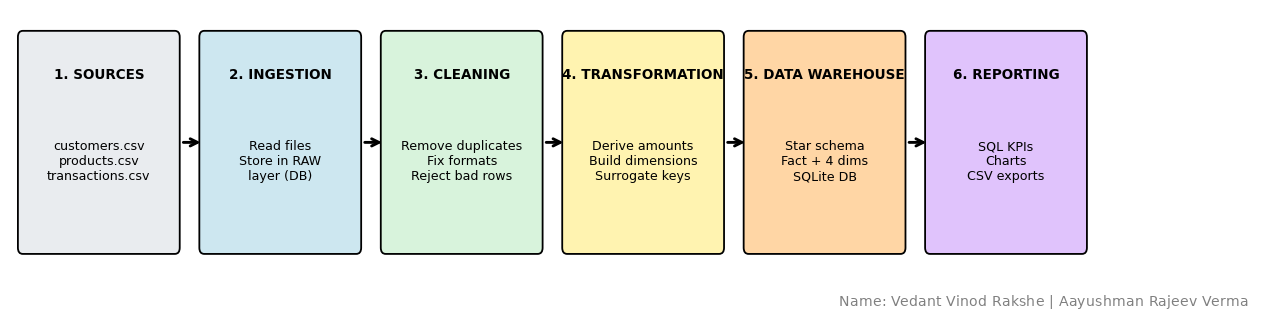

In [ ]:
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch
fig, ax = plt.subplots(figsize=(11, 2.6))
stages = [("1. SOURCES", "customers.csv\nproducts.csv\ntransactions.csv", "#e9ecef"),
          ("2. INGESTION", "Read files\nStore in RAW\nlayer (DB)", "#cde7f0"),
          ("3. CLEANING", "Remove duplicates\nFix formats\nReject bad rows", "#d8f3dc"),
          ("4. TRANSFORMATION", "Derive amounts\nBuild dimensions\nSurrogate keys", "#fff3b0"),
          ("5. DATA WAREHOUSE", "Star schema\nFact + 4 dims\nSQLite DB", "#ffd6a5"),
          ("6. REPORTING", "SQL KPIs\nCharts\nCSV exports", "#e0c3fc")]
for i, (title, body, color) in enumerate(stages):
    x = i * 1.85
    ax.add_patch(FancyBboxPatch((x, 0.2), 1.55, 1.7, boxstyle="round,pad=0.05", fc=color, ec="black"))
    ax.text(x + 0.775, 1.6, title, ha="center", va="center", fontsize=7.5, fontweight="bold")
    ax.text(x + 0.775, 0.9, body, ha="center", va="center", fontsize=7)
    if i < len(stages) - 1:
        ax.annotate("", xy=(x + 1.85, 1.05), xytext=(x + 1.6, 1.05), arrowprops=dict(arrowstyle="->", lw=1.6))
ax.set_xlim(-0.1, 11.2); ax.set_ylim(0, 2.1); ax.axis("off")
plt.gcf().text(0.99, 0.005, "Name: Vedant Vinod Rakshe | Aayushman Rajeev Verma", ha="right", va="bottom", fontsize=8, color="gray")
plt.savefig("p10_architecture.png", dpi=130, bbox_inches="tight")

## Task 2: Source Data Creation and Data Ingestion

In [ ]:
# Name: Vedant Vinod Rakshe
# Name: Aayushman Rajeev Verma
# MINI PROJECT: Retail Sales Data Warehouse (end-to-end data engineering solution)
print("Name: Vedant Vinod Rakshe | Group partner: Aayushman Rajeev Verma")
import os, sqlite3
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

run_log = []                                           # records every stage of the pipeline
def log(stage, rows_in, rows_out, note=""):
    run_log.append({"stage": stage, "rows_in": rows_in, "rows_out": rows_out, "note": note})

# ---------------------------------------------------------------
# STAGE 1 : SOURCE SYSTEM SIMULATION (creates the raw CSV files)
# ---------------------------------------------------------------
rng = np.random.default_rng(42)
catalog = {"Electronics": [("Laptop", 55000), ("Smartphone", 22000), ("Headphones", 2500),
                           ("Smart Watch", 6500), ("Mouse", 500), ("Keyboard", 1500)],
           "Furniture":   [("Office Chair", 3500), ("Study Desk", 9000), ("Bookshelf", 6000),
                           ("Table Lamp", 900), ("Sofa", 25000)],
           "Stationery":  [("Notebook", 60), ("Pen Pack", 120), ("Backpack", 1200),
                           ("Calculator", 850), ("Marker Set", 300)],
           "Fashion":     [("T-Shirt", 700), ("Jeans", 1800), ("Sneakers", 3200), ("Jacket", 4500)]}
rows = [(cat, n, p) for cat, items in catalog.items() for n, p in items]
products = pd.DataFrame({"product_id": [f"P{i+1:02d}" for i in range(len(rows))],
                         "product_name": [r[1] for r in rows], "category": [r[0] for r in rows],
                         "unit_price": [r[2] for r in rows]})

first = ["Amit", "Riya", "Neha", "Karan", "Sana", "Dev", "Tina", "Rahul", "Pooja",
         "Vikram", "Anjali", "Rohan"]
last = ["Shah", "Patil", "Rao", "Jain", "Khan", "Mehta", "Dsouza", "Verma", "Kulkarni", "Singh"]
cities = ["Mumbai", "Pune", "Delhi", "Nashik", "Surat", "Goa"]
n_cust = 150
fn, ln = rng.choice(first, n_cust), rng.choice(last, n_cust)
city = rng.choice(cities, n_cust).astype(object)
for i in range(n_cust):                                  # messy text formats
    r = rng.random()
    city[i] = city[i].lower() if r < 0.15 else (city[i].upper() + " " if r < 0.25 else city[i])
signup = pd.Timestamp("2025-06-01") + pd.to_timedelta(rng.integers(0, 120, n_cust), unit="D")
customers = pd.DataFrame({
    "customer_id": [f"C{i+1:03d}" for i in range(n_cust)], "name": [f"{a} {b}" for a, b in zip(fn, ln)],
    "email": [f"{a}.{b}{i+1}@Mail.com" for i, (a, b) in enumerate(zip(fn, ln))], "city": city,
    "signup_date": signup.strftime("%Y-%m-%d")})

n_tx = 1200
price_of = dict(zip(products["product_id"], products["unit_price"]))
pid = rng.choice(products["product_id"], n_tx)
qty = rng.integers(1, 6, n_tx)
qty = np.where(np.array([price_of[p] for p in pid]) > 20000, rng.integers(1, 3, n_tx), qty)
days = pd.Timestamp("2025-10-01") + pd.to_timedelta(rng.integers(0, 182, n_tx), unit="D")
tx = pd.DataFrame({
    "order_id": 100001 + np.arange(n_tx),
    "order_date": days.strftime("%Y-%m-%d"),
    "customer_id": rng.choice(customers["customer_id"], n_tx), "product_id": pid, "quantity": qty,
    "discount_pct": rng.choice([0, 0, 0, 5, 10, 15], n_tx),
    "payment_mode": rng.choice(["UPI", "CARD", "COD", "NETBANKING"], n_tx, p=[0.4, 0.3, 0.15, 0.15])})

# inject data-quality problems into the transactions
bad = rng.choice(n_tx, 72, replace=False)
tx.loc[bad[:24], "customer_id"] = None                   # missing customer
tx.loc[bad[24:42], "quantity"] = rng.choice([0, -1], 18) # invalid quantity
tx.loc[bad[42:60], "order_date"] = rng.choice(["N/A", "31-02-2026"], 18)   # invalid date
tx.loc[bad[60:72], "product_id"] = "P99"                 # unknown product
tx["payment_mode"] = [m.lower() if r < 0.1 else (m.title() if r < 0.2 else m)
                      for m, r in zip(tx["payment_mode"], rng.random(n_tx))]
tx = pd.concat([tx, tx.sample(36, random_state=1)], ignore_index=True)    # 36 duplicate rows

os.makedirs("source", exist_ok=True)
products.to_csv("source/products.csv", index=False)
customers.to_csv("source/customers.csv", index=False)
tx.to_csv("source/transactions.csv", index=False)

# ---------------------------------------------------------------
# STAGE 2 : DATA INGESTION  (read source files, store in RAW layer)
# ---------------------------------------------------------------
if os.path.exists("warehouse.db"):
    os.remove("warehouse.db")
conn = sqlite3.connect("warehouse.db")
raw = {name: pd.read_csv(f"source/{name}.csv") for name in ["customers", "products", "transactions"]}
for name, df in raw.items():
    df.assign(batch_id="BATCH_001").to_sql(f"raw_{name}", conn, if_exists="replace", index=False)
    log("ingest_" + name, len(df), len(df))
    print(f"Ingested {name:<13}: {len(df):>5} rows, {df.shape[1]} columns -> table raw_{name}")
print("\nSample of raw transactions:")
print(raw["transactions"].head(5).to_string(index=False))

Name: Vedant Vinod Rakshe | Group partner: Aayushman Rajeev Verma
Ingested customers    :   150 rows, 5 columns -> table raw_customers
Ingested products     :    20 rows, 4 columns -> table raw_products
Ingested transactions :  1236 rows, 7 columns -> table raw_transactions

Sample of raw transactions:
 order_id order_date customer_id product_id  quantity  discount_pct payment_mode
   100001 2026-02-04        C094        P01         2             0   NETBANKING
   100002 2026-01-06        C058        P01         1            10         card
   100003 2026-03-31        C042        P05         1            10         CARD
   100004 2026-02-18        C065        P18         1             5         CARD
   100005 2025-10-04        C047        P10         5             5          COD


## Task 3: Data Cleaning and Data Quality Report

Five validation rules are applied to the transactions: remove duplicates, invalid dates, invalid quantities, missing customer ids and unknown products. Payment modes and customer text fields are standardised.

In [ ]:
# ---------------------------------------------------------------
# STAGE 3 : DATA CLEANING  (with a data-quality report)
# ---------------------------------------------------------------
print("Name: Vedant Vinod Rakshe | Group partner: Aayushman Rajeev Verma")
t = raw["transactions"].copy()
dq = [("Raw rows received", len(t))]

n = len(t); t = t.drop_duplicates()
dq.append(("Duplicate rows removed", n - len(t)))

t["order_date"] = pd.to_datetime(t["order_date"], format="%Y-%m-%d", errors="coerce")
n = len(t); t = t[t["order_date"].notna()]
dq.append(("Invalid dates removed", n - len(t)))

n = len(t); t = t[t["quantity"] > 0]
dq.append(("Invalid quantity removed", n - len(t)))

n = len(t); t = t[t["customer_id"].notna()]
dq.append(("Missing customer_id removed", n - len(t)))

n = len(t); t = t[t["product_id"].isin(raw["products"]["product_id"])]
dq.append(("Unknown product removed", n - len(t)))

t["payment_mode"] = t["payment_mode"].str.strip().str.upper()        # UPI / Upi / upi -> UPI
dq.append(("Clean rows kept", len(t)))
clean_tx = t.reset_index(drop=True)

c = raw["customers"].copy()
c["name"] = c["name"].str.strip().str.title()
c["city"] = c["city"].str.strip().str.title()                         # 'PUNE ' -> 'Pune'
c["email"] = c["email"].str.strip().str.lower()
clean_cust = c.drop_duplicates("customer_id")
clean_prod = raw["products"].drop_duplicates("product_id")

print(pd.DataFrame(dq, columns=["Data quality check", "Rows"]).to_string(index=False))
print("\nCity values before:", sorted(raw["customers"]["city"].unique())[:6], "...")
print("City values after :", sorted(clean_cust["city"].unique()))
log("clean_transactions", len(raw["transactions"]), len(clean_tx), "5 quality rules applied")
log("clean_customers", len(raw["customers"]), len(clean_cust), "text standardised")

Name: Vedant Vinod Rakshe | Group partner: Aayushman Rajeev Verma
         Data quality check  Rows
          Raw rows received  1236
     Duplicate rows removed    36
      Invalid dates removed    18
   Invalid quantity removed    18
Missing customer_id removed    24
    Unknown product removed    12
            Clean rows kept  1128

City values before: ['DELHI ', 'Delhi', 'GOA ', 'Goa', 'MUMBAI ', 'Mumbai'] ...
City values after : ['Delhi', 'Goa', 'Mumbai', 'Nashik', 'Pune', 'Surat']


## Task 4: Data Transformation

Gross, discount and net amounts are derived, and the clean data is reshaped into dimension tables (date, customer, product, payment) and a fact table that uses surrogate keys.

In [ ]:
# ---------------------------------------------------------------
# STAGE 4 : TRANSFORMATION  (business columns + dimension tables)
# ---------------------------------------------------------------
# Derived measures
print("Name: Vedant Vinod Rakshe | Group partner: Aayushman Rajeev Verma")
f = clean_tx.merge(clean_prod[["product_id", "unit_price"]], on="product_id")
f["gross_amount"] = f["quantity"] * f["unit_price"]
f["discount_amount"] = (f["gross_amount"] * f["discount_pct"] / 100).round(2)
f["net_amount"] = f["gross_amount"] - f["discount_amount"]

# Dimension tables with surrogate keys
dim_date = pd.DataFrame({"full_date": pd.date_range(f["order_date"].min(), f["order_date"].max())})
dim_date["date_key"] = dim_date["full_date"].dt.strftime("%Y%m%d").astype(int)
dim_date["day_name"] = dim_date["full_date"].dt.day_name()
dim_date["month_name"] = dim_date["full_date"].dt.strftime("%b %Y")
dim_date["month_num"] = dim_date["full_date"].dt.strftime("%Y-%m")
dim_date["quarter"] = "Q" + dim_date["full_date"].dt.quarter.astype(str)
dim_date["year"] = dim_date["full_date"].dt.year
dim_date["is_weekend"] = dim_date["full_date"].dt.dayofweek.isin([5, 6]).astype(int)
dim_date["full_date"] = dim_date["full_date"].dt.strftime("%Y-%m-%d")
dim_date = dim_date[["date_key", "full_date", "day_name", "month_name", "month_num",
                     "quarter", "year", "is_weekend"]]

dim_customer = clean_cust.reset_index(drop=True)
dim_customer.insert(0, "customer_key", dim_customer.index + 1)
dim_product = clean_prod.reset_index(drop=True)
dim_product.insert(0, "product_key", dim_product.index + 1)
dim_payment = pd.DataFrame({"payment_mode": sorted(f["payment_mode"].unique())})
dim_payment.insert(0, "payment_key", dim_payment.index + 1)

# Fact table: replace business keys with surrogate keys
fact_sales = (f.assign(date_key=f["order_date"].dt.strftime("%Y%m%d").astype(int))
                .merge(dim_customer[["customer_key", "customer_id"]], on="customer_id")
                .merge(dim_product[["product_key", "product_id"]], on="product_id")
                .merge(dim_payment, on="payment_mode"))
fact_sales = fact_sales[["order_id", "date_key", "customer_key", "product_key", "payment_key", "quantity",
                         "unit_price", "discount_pct", "gross_amount", "discount_amount", "net_amount"]]
fact_sales.insert(0, "sales_key", range(1, len(fact_sales) + 1))

print("fact_sales rows :", len(fact_sales), "| dim_date:", len(dim_date), "| dim_customer:",
      len(dim_customer), "| dim_product:", len(dim_product), "| dim_payment:", len(dim_payment))
print("\nFact table sample:")
show = ["sales_key", "order_id", "date_key", "customer_key", "product_key", "quantity", "net_amount"]
print(fact_sales[show].head(5).to_string(index=False))
log("transform", len(clean_tx), len(fact_sales), "fact + 4 dimensions built")

Name: Vedant Vinod Rakshe | Group partner: Aayushman Rajeev Verma
fact_sales rows : 1128 | dim_date: 182 | dim_customer: 150 | dim_product: 20 | dim_payment: 4

Fact table sample:
 sales_key  order_id  date_key  customer_key  product_key  quantity  net_amount
         1    100001  20260204            94            1         2    110000.0
         2    100002  20260106            58            1         1     49500.0
         3    100003  20260331            42            5         1       450.0
         4    100004  20260218            65           18         1      1710.0
         5    100005  20251004            47           10         5      4275.0


## Task 5: Data Warehouse Design (Star Schema), Storage and Load

A star schema was chosen because it makes analytical queries simple and fast: one central fact table holds the measurable events (sales) and four dimension tables describe them.

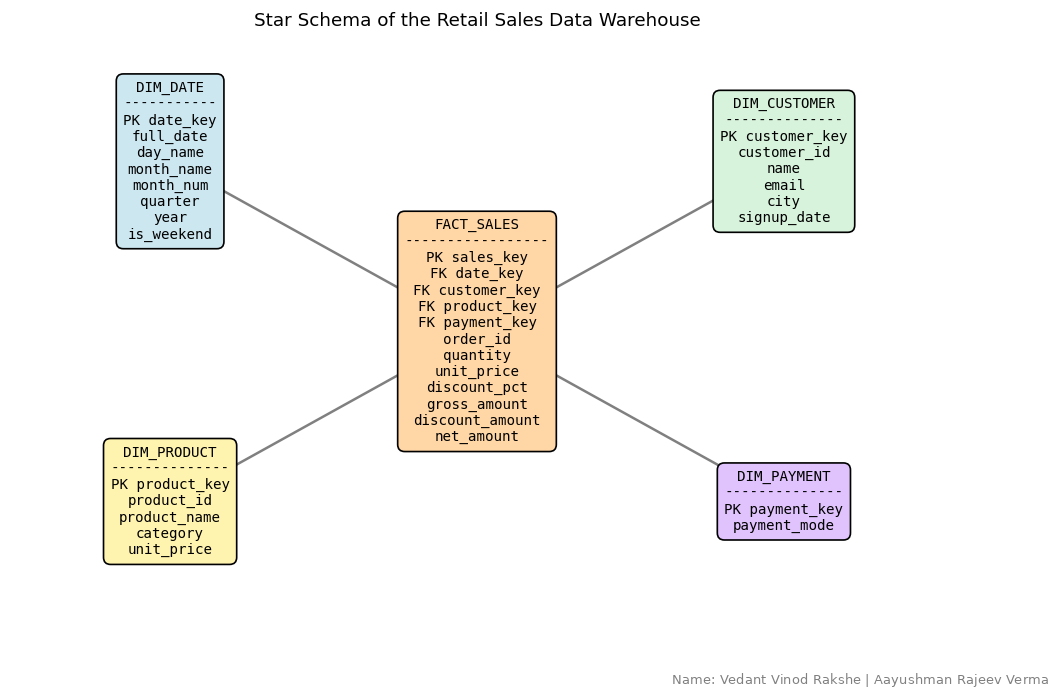

In [ ]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(10, 6.2))
def box(x, y, text, color):
    ax.text(x, y, text, ha="center", va="center", family="monospace", fontsize=8.5,
            bbox=dict(boxstyle="round,pad=0.5", fc=color, ec="black"), zorder=3)
centers = {"date": (1.7, 5.0), "cust": (8.3, 5.0), "prod": (1.7, 1.2), "pay": (8.3, 1.2)}
for (x, y) in centers.values():
    ax.plot([5, x], [3.1, y], color="gray", lw=1.5, zorder=1)
box(5, 3.1, "FACT_SALES\n-----------------\nPK sales_key\nFK date_key\nFK customer_key\nFK product_key\nFK payment_key\norder_id\nquantity\nunit_price\ndiscount_pct\ngross_amount\ndiscount_amount\nnet_amount", "#ffd6a5")
box(*centers["date"], "DIM_DATE\n-----------\nPK date_key\nfull_date\nday_name\nmonth_name\nmonth_num\nquarter\nyear\nis_weekend", "#cde7f0")
box(*centers["cust"], "DIM_CUSTOMER\n--------------\nPK customer_key\ncustomer_id\nname\nemail\ncity\nsignup_date", "#d8f3dc")
box(*centers["prod"], "DIM_PRODUCT\n--------------\nPK product_key\nproduct_id\nproduct_name\ncategory\nunit_price", "#fff3b0")
box(*centers["pay"], "DIM_PAYMENT\n--------------\nPK payment_key\npayment_mode", "#e0c3fc")
ax.set_xlim(0, 10); ax.set_ylim(0, 6.4); ax.axis("off")
ax.set_title("Star Schema of the Retail Sales Data Warehouse", fontsize=11)
plt.gcf().text(0.99, 0.005, "Name: Vedant Vinod Rakshe | Aayushman Rajeev Verma", ha="right", va="bottom", fontsize=8, color="gray")
plt.savefig("p10_star_schema.png", dpi=120, bbox_inches="tight")

In [ ]:
# ---------------------------------------------------------------
# STAGE 5 : STORAGE - DATA WAREHOUSE DESIGN (star schema) AND LOAD
# ---------------------------------------------------------------
print("Name: Vedant Vinod Rakshe | Group partner: Aayushman Rajeev Verma")
conn.execute("PRAGMA foreign_keys = ON")
conn.executescript("""
CREATE TABLE dim_date (date_key INTEGER PRIMARY KEY, full_date TEXT, day_name TEXT, month_name TEXT,
                       month_num TEXT, quarter TEXT, year INTEGER, is_weekend INTEGER);
CREATE TABLE dim_customer (customer_key INTEGER PRIMARY KEY, customer_id TEXT UNIQUE, name TEXT,
                           email TEXT, city TEXT, signup_date TEXT);
CREATE TABLE dim_product (product_key INTEGER PRIMARY KEY, product_id TEXT UNIQUE, product_name TEXT,
                          category TEXT, unit_price REAL);
CREATE TABLE dim_payment (payment_key INTEGER PRIMARY KEY, payment_mode TEXT UNIQUE);
CREATE TABLE fact_sales (
    sales_key INTEGER PRIMARY KEY, order_id INTEGER UNIQUE,
    date_key INTEGER REFERENCES dim_date(date_key),
    customer_key INTEGER REFERENCES dim_customer(customer_key),
    product_key INTEGER REFERENCES dim_product(product_key),
    payment_key INTEGER REFERENCES dim_payment(payment_key),
    quantity INTEGER CHECK (quantity > 0), unit_price REAL, discount_pct REAL,
    gross_amount REAL, discount_amount REAL, net_amount REAL);
CREATE INDEX idx_fact_date ON fact_sales(date_key);
CREATE INDEX idx_fact_customer ON fact_sales(customer_key);
CREATE INDEX idx_fact_product ON fact_sales(product_key);
""")
for name, df in [("dim_date", dim_date), ("dim_customer", dim_customer), ("dim_product", dim_product),
                 ("dim_payment", dim_payment), ("fact_sales", fact_sales)]:
    df.to_sql(name, conn, if_exists="append", index=False)
    print(f"{name:<13} loaded: {conn.execute(f'SELECT COUNT(*) FROM {name}').fetchone()[0]:>5} rows")
conn.commit()

violations = conn.execute("PRAGMA foreign_key_check").fetchall()
print("\nForeign key violations:", len(violations))
print("Revenue check -> Pandas:", round(fact_sales["net_amount"].sum(), 2),
      "| SQL:", round(conn.execute("SELECT SUM(net_amount) FROM fact_sales").fetchone()[0], 2))
n_fact = conn.execute("SELECT COUNT(*) FROM fact_sales").fetchone()[0]
log("load_warehouse", len(fact_sales), n_fact, "FK check passed")

Name: Vedant Vinod Rakshe | Group partner: Aayushman Rajeev Verma
dim_date      loaded:   182 rows
dim_customer  loaded:   150 rows
dim_product   loaded:    20 rows
dim_payment   loaded:     4 rows
fact_sales    loaded:  1128 rows

Foreign key violations: 0
Revenue check -> Pandas: 15239825.5 | SQL: 15239825.5


## Task 6: Reporting and Analytics

In [ ]:
# ---------------------------------------------------------------
# STAGE 6 : REPORTING  (SQL on the star schema)
# ---------------------------------------------------------------
print("Name: Vedant Vinod Rakshe | Group partner: Aayushman Rajeev Verma")
q = lambda sql: pd.read_sql(sql, conn)

kpi = q("""SELECT COUNT(*) AS orders, SUM(quantity) AS units,
                  ROUND(SUM(net_amount), 2) AS net_revenue,
                  ROUND(SUM(discount_amount), 2) AS discount_given,
                  ROUND(AVG(net_amount), 2) AS avg_order_value
           FROM fact_sales""")
print("KEY PERFORMANCE INDICATORS"); print(kpi.to_string(index=False))

monthly = q("""SELECT d.month_num AS month, COUNT(*) AS orders, ROUND(SUM(f.net_amount), 2) AS net_revenue
               FROM fact_sales f JOIN dim_date d ON d.date_key = f.date_key
               GROUP BY d.month_num ORDER BY d.month_num""")
print("\nMONTHLY REVENUE"); print(monthly.to_string(index=False))

by_cat = q("""SELECT p.category, SUM(f.quantity) AS units, ROUND(SUM(f.net_amount), 2) AS net_revenue
              FROM fact_sales f JOIN dim_product p ON p.product_key = f.product_key
              GROUP BY p.category ORDER BY net_revenue DESC""")
print("\nREVENUE BY CATEGORY"); print(by_cat.to_string(index=False))

by_city = q("""SELECT c.city, COUNT(*) AS orders, ROUND(SUM(f.net_amount), 2) AS net_revenue
               FROM fact_sales f JOIN dim_customer c ON c.customer_key = f.customer_key
               GROUP BY c.city ORDER BY net_revenue DESC""")
print("\nREVENUE BY CITY"); print(by_city.to_string(index=False))

top_products = q("""SELECT p.product_name, p.category, SUM(f.quantity) AS units,
                           ROUND(SUM(f.net_amount), 2) AS net_revenue
                    FROM fact_sales f JOIN dim_product p ON p.product_key = f.product_key
                    GROUP BY p.product_name ORDER BY net_revenue DESC LIMIT 5""")
print("\nTOP 5 PRODUCTS"); print(top_products.to_string(index=False))

top_customers = q("""SELECT c.name, c.city, COUNT(*) AS orders,
                            ROUND(SUM(f.net_amount), 2) AS net_revenue
                     FROM fact_sales f JOIN dim_customer c ON c.customer_key = f.customer_key
                     GROUP BY c.customer_key ORDER BY net_revenue DESC LIMIT 5""")
print("\nTOP 5 CUSTOMERS"); print(top_customers.to_string(index=False))

pay = q("""SELECT y.payment_mode, COUNT(*) AS orders, ROUND(SUM(f.net_amount), 2) AS net_revenue
           FROM fact_sales f JOIN dim_payment y ON y.payment_key = f.payment_key
           GROUP BY y.payment_mode ORDER BY orders DESC""")
print("\nPAYMENT MODES"); print(pay.to_string(index=False))

weekend = q("""SELECT CASE d.is_weekend WHEN 1 THEN 'Weekend' ELSE 'Weekday' END AS day_type,
                      COUNT(*) AS orders, ROUND(AVG(f.net_amount), 2) AS avg_order_value
               FROM fact_sales f JOIN dim_date d ON d.date_key = f.date_key GROUP BY d.is_weekend""")
print("\nWEEKDAY vs WEEKEND"); print(weekend.to_string(index=False))
log("reporting", len(fact_sales), 8, "8 report queries")

Name: Vedant Vinod Rakshe | Group partner: Aayushman Rajeev Verma
KEY PERFORMANCE INDICATORS
 orders  units  net_revenue  discount_given  avg_order_value
   1128   3112   15239825.5        816984.5         13510.48

MONTHLY REVENUE
  month  orders  net_revenue
2025-10     188    2607159.5
2025-11     189    2220079.0
2025-12     177    2802472.0
2026-01     198    3123208.0
2026-02     189    2366325.0
2026-03     187    2120582.0

REVENUE BY CATEGORY
   category  units  net_revenue
Electronics    820    7548200.0
  Furniture    837    5600050.0
    Fashion    680    1729335.0
 Stationery    775     362240.5

REVENUE BY CITY
  city  orders  net_revenue
Mumbai     244    3436139.5
  Pune     248    3282973.5
   Goa     208    2661399.0
 Surat     165    2590624.0
Nashik     149    2185402.5
 Delhi     114    1083287.0

TOP 5 PRODUCTS
product_name    category  units  net_revenue
      Laptop Electronics     81    4213000.0
        Sofa   Furniture     93    2188750.0
  Smartphone Electro

## Task 7: Dashboard, Report Export and Pipeline Run Summary

Name: Vedant Vinod Rakshe | Group partner: Aayushman Rajeev Verma
Reports exported to the reports/ folder:
   by_category.csv
   by_city.csv
   kpi.csv
   monthly_revenue.csv
   top_customers.csv
   top_products.csv


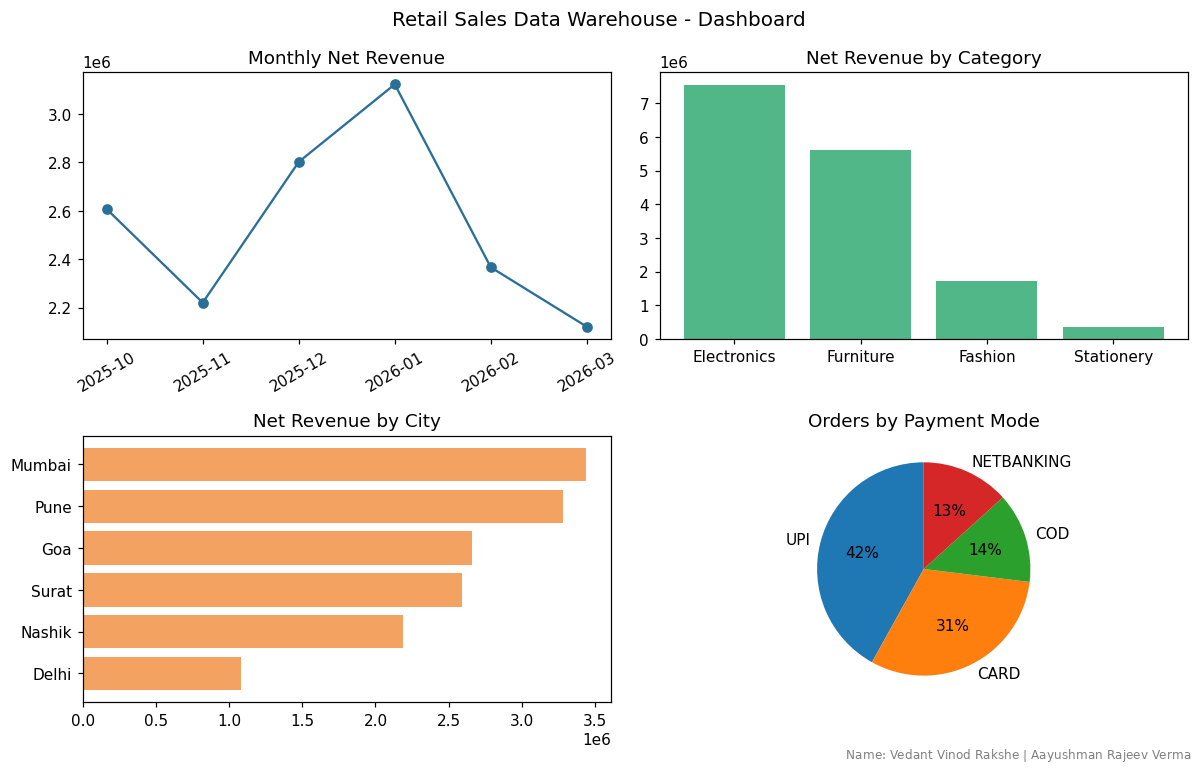

In [ ]:
# ---- Dashboard charts and report exports
print("Name: Vedant Vinod Rakshe | Group partner: Aayushman Rajeev Verma")
fig, ax = plt.subplots(2, 2, figsize=(11, 7))
ax[0, 0].plot(monthly["month"], monthly["net_revenue"], marker="o", color="#2a6f97")
ax[0, 0].set_title("Monthly Net Revenue"); ax[0, 0].tick_params(axis="x", rotation=30)
ax[0, 1].bar(by_cat["category"], by_cat["net_revenue"], color="#52b788")
ax[0, 1].set_title("Net Revenue by Category")
ax[1, 0].barh(by_city["city"], by_city["net_revenue"], color="#f4a261")
ax[1, 0].set_title("Net Revenue by City"); ax[1, 0].invert_yaxis()
ax[1, 1].pie(pay["orders"], labels=pay["payment_mode"], autopct="%1.0f%%", startangle=90)
ax[1, 1].set_title("Orders by Payment Mode")
plt.suptitle("Retail Sales Data Warehouse - Dashboard", fontsize=13)
plt.tight_layout()
plt.gcf().text(0.99, 0.005, "Name: Vedant Vinod Rakshe | Aayushman Rajeev Verma", ha="right", va="bottom", fontsize=8, color="gray")
plt.savefig("p10_dashboard.png", dpi=110, bbox_inches="tight")
plt.show()

os.makedirs("reports", exist_ok=True)
for name, df in [("kpi", kpi), ("monthly_revenue", monthly), ("by_category", by_cat),
                 ("by_city", by_city), ("top_products", top_products), ("top_customers", top_customers)]:
    df.to_csv(f"reports/{name}.csv", index=False)
print("Reports exported to the reports/ folder:")
for file in sorted(os.listdir("reports")):
    print("  ", file)

In [ ]:
# ---- Pipeline run summary (audit trail of all stages)
print("Name: Vedant Vinod Rakshe | Group partner: Aayushman Rajeev Verma")
print(pd.DataFrame(run_log).to_string(index=False))
conn.close()

Name: Vedant Vinod Rakshe | Group partner: Aayushman Rajeev Verma
              stage  rows_in  rows_out                      note
   ingest_customers      150       150                          
    ingest_products       20        20                          
ingest_transactions     1236      1236                          
 clean_transactions     1236      1128   5 quality rules applied
    clean_customers      150       150         text standardised
          transform     1128      1128 fact + 4 dimensions built
     load_warehouse     1128      1128           FK check passed
          reporting     1128         8          8 report queries


**Conclusion:** An end-to-end data engineering solution was designed and implemented by the group. Raw CSV data was ingested into a raw layer, cleaned using five quality rules, transformed into business measures and dimensions, stored in a star-schema data warehouse with primary keys, foreign keys and indexes, and used to produce KPI, trend, product, city, customer and payment reports along with a dashboard. The final run summary shows the number of rows entering and leaving every stage.